# House Price Prediction — исследование линейных моделей и регуляризации

## Постановка задачи

Стоимость жилого дома зависит от площади, расположения, состояния, года постройки и других характеристик. Цель проекта — построить модель **регрессии**, которая по описанию объекта прогнозирует его цену продажи (`SalePrice`). Исследование выполнено на данных соревнования [House Prices — Advanced Regression Techniques](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques).

## Актуальность

Автоматизированная оценка недвижимости полезна для предварительного анализа рынка, сравнения объектов и поддержки решений покупателей, продавцов и аналитиков. Линейные модели дают интерпретируемую отправную точку и позволяют исследовать влияние регуляризации при большом числе закодированных признаков.

## Цели исследования

- Изучить распределение цен, пропуски и взаимосвязи признаков.
- Построить единый пайплайн предобработки числовых и категориальных переменных.
- Сравнить Linear Regression, Ridge, Lasso и ElasticNet.
- Проанализировать зависимость ошибки и коэффициентов от силы регуляризации.
- Сформировать прогнозы в формате Kaggle.

## Выбор метрик

Основная метрика — **RMSE в логарифмическом масштабе**, поскольку целевая переменная преобразована как `log(SalePrice)`. RMSE сильнее штрафует крупные отклонения и позволяет сравнивать варианты регуляризации. На исходной шкале цены её значение напрямую не интерпретируется в долларах. **R²** рассматривается как возможная дополнительная метрика, но в сохранённых экспериментах основной критерий — RMSE.

> **Воспроизводимость:** код и все сохранённые результаты выполнения оставлены без изменений. Ноутбук использует пути Google Colab/Drive, указанные в исходном коде. Для запуска в другом окружении потребуется адаптировать пути. Отложенная выборка использовалась для настройки регуляризации, поэтому это исследовательское сравнение, а не независимый финальный тест.

---


In [ ]:
import numpy as np
import pandas as pd
import scipy.stats as sps
import scipy
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import root_mean_squared_error as rmse
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from time import time
from tqdm.notebook import tqdm
from typing import Tuple, List, Dict, Any, Optional

sns.set_theme(palette='Set2', font_scale=1.2)

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score
from sklearn.base import clone

from sklearn.model_selection import (
    train_test_split,
    GroupKFold,
    GroupShuffleSplit,
    KFold,
    ShuffleSplit,
    StratifiedKFold,
    StratifiedShuffleSplit,
    cross_val_score,
    cross_val_predict,
)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Исследование данных и подготовка признаков

Цель этапа — изучить структуру данных о жилой недвижимости, распределение цен и особенности признаков перед обучением регрессионных моделей.

### 1.1. Загрузка и первичный анализ

Используется датасет **House Prices — Advanced Regression Techniques**: характеристики жилых домов и фактические цены продажи (`SalePrice`). Рассмотрим размер таблицы, описательные статистики, распределение целевой переменной и особенности объектов по районам.

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/ML/house-prices-advanced-regression-techniques/train.csv')
test = pd.read_csv('/content/drive/MyDrive/ML/house-prices-advanced-regression-techniques/test.csv')

In [ ]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [ ]:
df.shape

(1460, 81)

In [ ]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


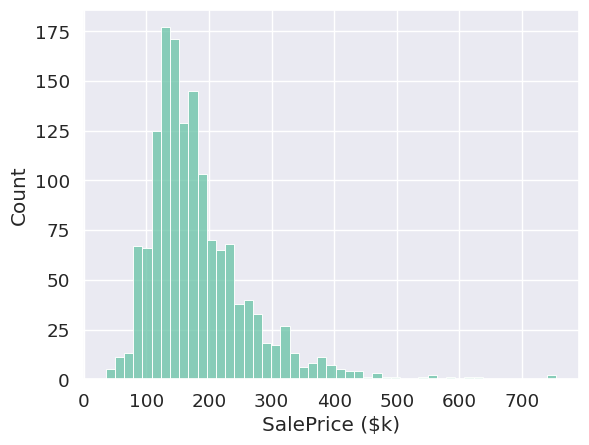

In [ ]:
sns.histplot(df['SalePrice']/1000)
plt.xlabel('SalePrice ($k)')
plt.show()

In [ ]:
df_grouped = df.groupby('Neighborhood').count()
df_grouped

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
Neighborhood,,,,,,,,,,,,,,,,,,,,,
Blmngtn,17,17,17,14,17,17,0,17,17,17,...,17,0,0,0,17,17,17,17,17,17
Blueste,2,2,2,2,2,2,0,2,2,2,...,2,0,2,0,2,2,2,2,2,2
BrDale,16,16,16,16,16,16,0,16,16,16,...,16,0,0,0,16,16,16,16,16,16
BrkSide,58,58,58,51,58,58,5,58,58,58,...,58,0,13,4,58,58,58,58,58,58
ClearCr,28,28,28,13,28,28,0,28,28,28,...,28,0,3,2,28,28,28,28,28,28
CollgCr,150,150,150,126,150,150,0,150,150,150,...,150,0,18,2,150,150,150,150,150,150
Crawfor,51,51,51,41,51,51,1,51,51,51,...,51,0,13,1,51,51,51,51,51,51
Edwards,100,100,100,92,100,100,6,100,100,100,...,100,2,23,3,100,100,100,100,100,100
Gilbert,79,79,79,49,79,79,0,79,79,79,...,79,0,2,3,79,79,79,79,79,79


<Axes: ylabel='Neighborhood'>

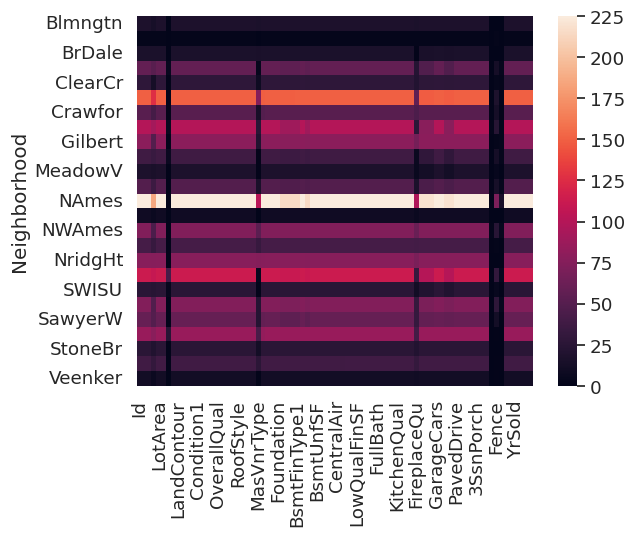

In [ ]:
plt.figure()
sns.heatmap(df_grouped)

### 1.2. Формирование признаков и целевой переменной

Исключаем `Id` как технический идентификатор и отделяем `SalePrice`. Для моделирования используем **натуральный логарифм цены**: он уменьшает асимметрию распределения и позволяет оценивать ошибки в логарифмическом масштабе. Наблюдения без целевой переменной не используются.

In [ ]:
X = df.drop(columns=['SalePrice', 'Id'])
y = df['SalePrice']
y.dropna(inplace = True)
y = np.log(y)
X = X.loc[y.index]
X.shape, y.shape

((1460, 79), (1460,))

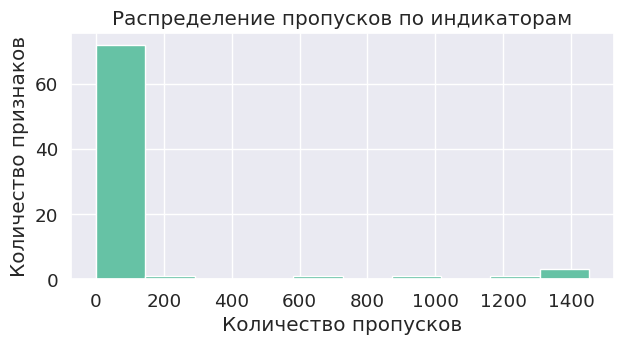

In [ ]:
nans = X.isna().sum()
plt.figure(figsize=(7, 3.2))
nans.hist()
plt.xlabel("Количество пропусков")
plt.ylabel("Количество признаков")
plt.title("Распределение пропусков по индикаторам");

Пропуски не всегда означают ошибку измерения: для некоторых характеристик недвижимости отсутствие значения может отражать отсутствие соответствующего объекта или удобства. Поэтому не удаляем такие столбцы автоматически; изучаем их структуру и применяем преобразования в составе пайплайна. Далее фиксируем случайное разбиение на обучающую и отложенную выборки.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1022, 79), (438, 79), (1022,), (438,))

### 1.3. Пайплайн преобразования признаков

Числовые признаки заполняются медианами и масштабируются в диапазон [−1, 1]. Категориальные кодируются методом one-hot encoding с обработкой ранее не встречавшихся категорий. Пайплайн позволяет применять одинаковые преобразования при обучении и прогнозировании.

In [ ]:
num_cols = X_train.select_dtypes(include=['float64', 'int64']).columns.tolist()
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

numerical_prep = Pipeline(steps=[
  ('median_imputer', SimpleImputer(strategy = 'median')),
  ('minmax', MinMaxScaler(feature_range=(-1,1)))

  ])

categorial_prep = Pipeline(steps=[
  ('ohe', OneHotEncoder(sparse_output = False, handle_unknown='ignore'))
])

preprocess = ColumnTransformer(
    transformers = [
        ('num', numerical_prep, num_cols),
        ('cat', categorial_prep, cat_cols)
    ])

### 1.4. Корреляции преобразованных признаков

Изучаем абсолютные значения попарных корреляций после кодирования признаков. Сильная корреляция может указывать на мультиколлинеарность, особенно значимую для интерпретации коэффициентов линейных моделей.

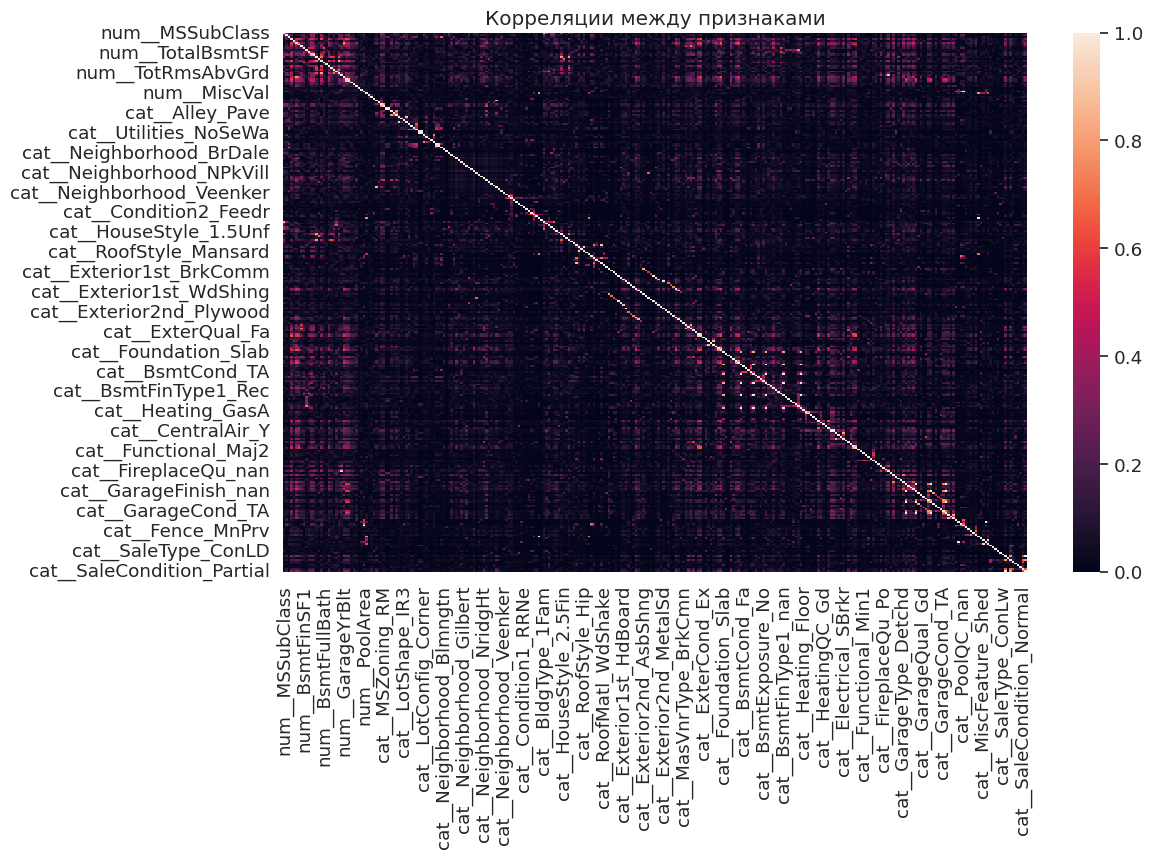

In [ ]:
# Преобразуем признаки
X_transformed = preprocess.fit_transform(X_train)

# Превращаем результат в DataFrame
X_transformed = pd.DataFrame(
    X_transformed,
    columns=preprocess.get_feature_names_out(),
    index=X_train.index
)

# Корреляционная матрица
corr_matrix = X_transformed.corr().abs()

plt.figure(figsize=(12, 7))
sns.heatmap(corr_matrix)
plt.title("Корреляции между признаками")
plt.show()

### 1.5. Анализ пропущенных значений

Отдельно рассматриваем числовые и категориальные столбцы с пропусками, чтобы понять масштаб проблемы и смысл отсутствующих значений. Далее используется выбранный пайплайн предобработки.

In [ ]:
num_nan_counts = df.select_dtypes(include = ['number']).isna().sum()
num_nan_counts = num_nan_counts[num_nan_counts > 0]
num_nan_cols = num_nan_counts.index
num_nan_counts

,0
LotFrontage,259
MasVnrArea,8
GarageYrBlt,81


In [ ]:
obj_nan_counts = X.select_dtypes(include = ['object', 'category']).isna().sum()
obj_nan_counts = obj_nan_counts[obj_nan_counts > 0]
obj_nan_cols = obj_nan_counts.index
obj_nan_counts

,0
Alley,1369
MasVnrType,872
BsmtQual,37
BsmtCond,37
BsmtExposure,38
BsmtFinType1,37
BsmtFinType2,38
Electrical,1
FireplaceQu,690
GarageType,81


In [ ]:
for col in obj_nan_cols:
  print(f'{col}, пропусков {obj_nan_counts[col]}, уникальные значения: {X[col].dropna().unique()}')

Alley, пропусков 1369, уникальные значения: ['Grvl' 'Pave']
MasVnrType, пропусков 872, уникальные значения: ['BrkFace' 'Stone' 'BrkCmn']
BsmtQual, пропусков 37, уникальные значения: ['Gd' 'TA' 'Ex' 'Fa']
BsmtCond, пропусков 37, уникальные значения: ['TA' 'Gd' 'Fa' 'Po']
BsmtExposure, пропусков 38, уникальные значения: ['No' 'Gd' 'Mn' 'Av']
BsmtFinType1, пропусков 37, уникальные значения: ['GLQ' 'ALQ' 'Unf' 'Rec' 'BLQ' 'LwQ']
BsmtFinType2, пропусков 38, уникальные значения: ['Unf' 'BLQ' 'ALQ' 'Rec' 'LwQ' 'GLQ']
Electrical, пропусков 1, уникальные значения: ['SBrkr' 'FuseF' 'FuseA' 'FuseP' 'Mix']
FireplaceQu, пропусков 690, уникальные значения: ['TA' 'Gd' 'Fa' 'Ex' 'Po']
GarageType, пропусков 81, уникальные значения: ['Attchd' 'Detchd' 'BuiltIn' 'CarPort' 'Basment' '2Types']
GarageFinish, пропусков 81, уникальные значения: ['RFn' 'Unf' 'Fin']
GarageQual, пропусков 81, уникальные значения: ['TA' 'Fa' 'Gd' 'Ex' 'Po']
GarageCond, пропусков 81, уникальные значения: ['TA' 'Fa' 'Gd' 'Po' 'Ex']

In [ ]:
num_cols = X_train.select_dtypes(include=['float64', 'int64']).columns.tolist()
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

numerical_prep = Pipeline(steps=[
  ('median_imputer', SimpleImputer(strategy = 'median')),
  ('minmax', MinMaxScaler(feature_range=(-1,1)))

  ])

categorial_prep = Pipeline(steps=[
  ('ohe', OneHotEncoder(sparse_output = False, handle_unknown='ignore'))
])

preprocess = ColumnTransformer(
    transformers = [
        ('num', numerical_prep, num_cols),
        ('cat', categorial_prep, cat_cols)
    ])

## 2. Регрессионные модели и регуляризация

Сравниваем линейную регрессию без регуляризации, **Ridge** (L2), **Lasso** (L1) и **ElasticNet** (L1 + L2). Основная метрика — **RMSE между логарифмами фактических и предсказанных цен**. Она штрафует большие ошибки и соответствует масштабу, в котором обучаются модели. Дополнительно полезна R² для оценки объяснённой доли вариации целевой переменной, хотя в данном эксперименте она не является основной метрикой.

**Особенность протокола:** в сохранённом эксперименте RMSE на отложенной выборке также использовалась при выборе регуляризации. Поэтому эти значения следует рассматривать как исследовательские, а не как независимую итоговую оценку после настройки. Для строгой оценки понадобилась бы отдельная validation-выборка или кросс-валидация.

In [ ]:
models = {
    'No regularisation': LinearRegression(),
    'Ridge': Ridge(alpha = 1.0),
    'Lasso': Lasso(alpha=1.0),
    'ElasticNet': ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=10000)
}


for name, estimator in models.items():
  model = Pipeline(
    steps =[
        ('preprocessor', preprocess),
        ('estimator', estimator)])

  model.fit(X_train, y_train)
  y_pred_train = model.predict(X_train)
  y_pred_test = model.predict(X_test)

  train_rmse = rmse(y_train, y_pred_train)
  test_rmse = rmse(y_test, y_pred_test)
  print(name)
  print(f"RMSE на тренировочной выборке {train_rmse}")
  print(f"RMSE на тестовой выборке {test_rmse}")
  print()


No regularisation
RMSE на тренировочной выборке 0.0896646752927144
RMSE на тестовой выборке 0.1428611218595963

Ridge
RMSE на тренировочной выборке 0.0973816834343089
RMSE на тестовой выборке 0.13280584005762747

Lasso
RMSE на тренировочной выборке 0.3937075656169874
RMSE на тестовой выборке 0.4121973536243332

ElasticNet
RMSE на тренировочной выборке 0.3937075656169874
RMSE на тестовой выборке 0.4121973536243332



In [ ]:
def train_grid(
    estimator,
    log_alpha_bounds: Tuple[float, float],
    resolution: int,
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_test: pd.DataFrame,
    y_test: pd.Series
):

#разделение на числовые и категориальные переменные
    num_cols = X_train.select_dtypes(include=['float64', 'int64']).columns.tolist()
    cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

#создание Pipeline
    numerical_prep = Pipeline(steps=[
      ('median_imputer', SimpleImputer(strategy = 'median')),
      ('minmax', MinMaxScaler(feature_range=(-1,1)))
      ])

    categorial_prep = Pipeline(steps=[
      ('ohe', OneHotEncoder(sparse_output = False, handle_unknown='ignore'))
    ])

    preprocess = ColumnTransformer(
        transformers = [
            ('num', numerical_prep, num_cols),
            ('cat', categorial_prep, cat_cols)
        ])

#Разметка параметров регуляризации
    log_alpha_values = np.linspace(log_alpha_bounds[0], log_alpha_bounds[1], resolution)
    alpha_values = 10**log_alpha_values

#Обучение
    coefs_list = []
    rmse_train_list = []
    rmse_test_list = []

    for alpha_val in tqdm(alpha_values):
        try:
            current_estimator = clone(estimator)
            current_estimator.set_params(alpha = alpha_val)
            model = Pipeline(steps=[
                ("preprocessor", preprocess),
                ("model", current_estimator)
            ])

            model.fit(X_train, y_train)
            y_pred_train = model.predict(X_train)
            y_pred_test = model.predict(X_test)

            train_rmse = rmse(y_train, y_pred_train)
            test_rmse = rmse(y_test, y_pred_test)
            coefs_list.append(
                model.named_steps['model'].coef_.copy()
            )
            rmse_train_list.append(train_rmse)
            rmse_test_list.append(test_rmse)

        except Exception as e:
            print(f"Error for alpha={alpha_val:.6f}: {e}")
            coefs_list.append(None)
            rmse_train_list.append(np.nan)
            rmse_test_list.append(np.nan)


    return coefs_list, rmse_train_list, rmse_test_list


In [ ]:
log_alpha_values = np.linspace(-3, 5, 50)

In [ ]:
coefs_Ridge, rmse_train_Ridge, rmse_test_Ridge = train_grid(Ridge(), (-3,5), 50, X_train, y_train, X_test, y_test)

  0%|          | 0/50 [00:00<?, ?it/s]

In [ ]:
coefs_Lasso, rmse_train_Lasso, rmse_test_Lasso = train_grid(Lasso(max_iter = 5000), (-3,5), 50, X_train, y_train, X_test, y_test)

  0%|          | 0/50 [00:00<?, ?it/s]

In [ ]:
coefs_EN, rmse_train_EN, rmse_test_EN = train_grid(ElasticNet(l1_ratio=0.5,
        max_iter=10000), (-3,5), 50, X_train, y_train, X_test, y_test)

  0%|          | 0/50 [00:00<?, ?it/s]

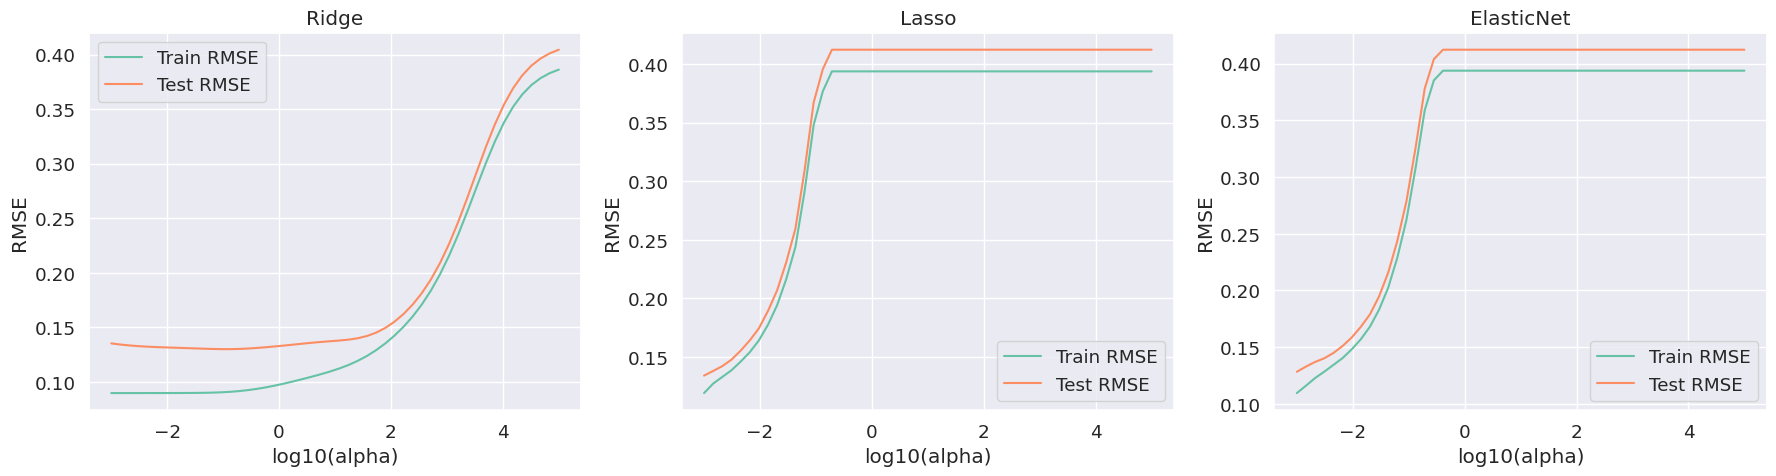

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

models = [
    ('Ridge', log_alpha_values, rmse_train_Ridge, rmse_test_Ridge),
    ('Lasso', log_alpha_values, rmse_train_Lasso, rmse_test_Lasso),
    ('ElasticNet', log_alpha_values, rmse_train_EN, rmse_test_EN)
]

for ax, (name, log_alphas, train, test) in zip(axes, models):
    ax.plot(log_alphas, train, label='Train RMSE')
    ax.plot(log_alphas, test, label='Test RMSE')
    ax.set_xlabel('log10(alpha)')
    ax.set_ylabel('RMSE')
    ax.set_title(name)
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

### 2.1. Влияние силы регуляризации на качество

При больших значениях `alpha` коэффициенты сильнее сжимаются, что ограничивает гибкость модели. На графиках видно, как это влияет на RMSE обучающей и отложенной выборок; рост ошибки при чрезмерной регуляризации согласуется с недообучением.

### 2.2. Траектории коэффициентов

Сравним изменение коэффициентов Ridge, Lasso и ElasticNet при увеличении `alpha`. L1-регуляризация может обнулять коэффициенты, тогда как L2 обычно уменьшает их непрерывно.

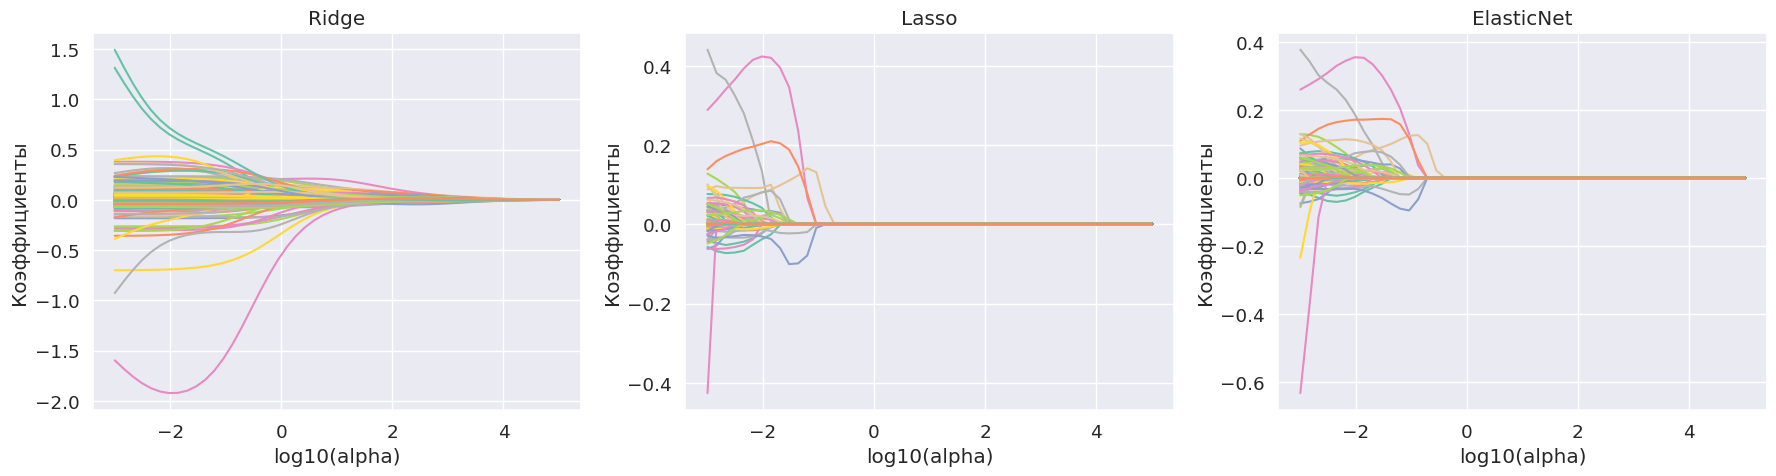

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

models = [
    ('Ridge', coefs_Ridge),
    ('Lasso', coefs_Lasso),
    ('ElasticNet', coefs_EN)
]

for ax, (name, coefs) in zip(axes, models):
    ax.plot(log_alpha_values, np.array(coefs))
    ax.set_xlabel('log10(alpha)')
    ax.set_ylabel('Коэффициенты')
    ax.set_title(name)
    ax.grid(True)

plt.tight_layout()
plt.show()

### 2.3. Сравнение подобранных конфигураций

Для каждой регуляризованной модели находим значение `alpha` с минимальной наблюдаемой RMSE на отложенной выборке. **Ограничение:** поскольку эта же выборка участвует в выборе гиперпараметров, полученная минимальная ошибка может быть оптимистичной; её не следует трактовать как несмещённую оценку качества на новых данных.

In [ ]:
results = {
    "Ridge": (log_alpha_values, rmse_test_Ridge),
    "Lasso": (log_alpha_values, rmse_test_Lasso),
    "ElasticNet": (log_alpha_values, rmse_test_EN)
}
rmse_fin = 100

for name, (log_alphas, errors) in results.items():
    best_idx = np.nanargmin(errors)

    best_alpha = 10 ** log_alphas[best_idx]
    best_rmse = errors[best_idx]
    if best_rmse < rmse_fin:
      name_min = name
      rmse_fin = best_rmse
    print(
        f"{name}: best RMSE = {best_rmse:.2f}, "
        f"alpha = {best_alpha:.5g}"
    )

print('best of all', name_min)

Ridge: best RMSE = 0.13, alpha = 0.13257
Lasso: best RMSE = 0.13, alpha = 0.001
ElasticNet: best RMSE = 0.13, alpha = 0.001
best of all ElasticNet


## 3. Прогнозирование для Kaggle

После сравнения моделей формируем прогнозы для объектов из `test.csv` соревнования. Важно возвращать предсказания из логарифмической шкалы к исходной цене перед сохранением `SalePrice`.

In [ ]:
X_test_kaggle = pd.read_csv('/content/drive/MyDrive/ML/house-prices-advanced-regression-techniques/test.csv')

In [ ]:
model = Pipeline(
    steps =[
        ('preprocessor', preprocess),
        ('estimator', ElasticNet(alpha = 0.001, l1_ratio=0.5, max_iter=10000))])
model.fit(X, y)
y_test_kaggle = model.predict(X_test_kaggle)
y_test_kaggle

array([11.66153936, 11.90788989, 12.04573997, ..., 11.99267265,
       11.64787712, 12.35280804], shape=(1459,))

In [ ]:
test_ids = pd.read_csv('/content/drive/MyDrive/ML/house-prices-advanced-regression-techniques/test.csv')['Id']

submission = pd.DataFrame({
    'Id': test_ids,
    'SalePrice': y_test_kaggle
})
submission.to_csv('/content/drive/MyDrive/ML/house-prices-advanced-regression-techniques/submission.csv', index=False)
submission

,Id,SalePrice
0,1461,11.661539
1,1462,11.907890
2,1463,12.045740
3,1464,12.190348
4,1465,12.194275
...,...,...
1454,2915,11.336784
1455,2916,11.353818
1456,2917,11.992673
1457,2918,11.647877


### 3.1. Финальный вариант на Ridge

Обучаем Ridge на доступной размеченной выборке с выбранным коэффициентом регуляризации и формируем таблицу предсказаний. Здесь применяется обратное преобразование `np.exp`, поэтому цены возвращаются в исходный масштаб.

In [ ]:
model = Pipeline(
    steps =[
        ('preprocessor', preprocess),
        ('estimator', Ridge(alpha = 0.13257))])
model.fit(X, y)
y_test_kaggle = np.exp(model.predict(X_test_kaggle))

submission2 = pd.DataFrame({
    'Id': test_ids,
    'SalePrice': y_test_kaggle
})
submission2.to_csv('/content/drive/MyDrive/ML/house-prices-advanced-regression-techniques/submission2.csv', index=False)
submission2

,Id,SalePrice
0,1461,120559.341413
1,1462,154583.204266
2,1463,180404.350543
3,1464,201853.997775
4,1465,195273.519980
...,...,...
1454,2915,83340.951982
1455,2916,84981.273640
1456,2917,172240.186527
1457,2918,113340.602605


## 4. Выводы и ограничения

В работе исследованы способы подготовки смешанных числовых и категориальных признаков и влияние L1/L2-регуляризации на линейные регрессионные модели. Графики ошибок и коэффициентов позволяют сопоставить качество и степень сжатия параметров.

**Ограничения сохранённого эксперимента:** гиперпараметры подбирались по отложенной выборке; независимой финальной оценки нет. В промежуточном варианте ElasticNet прогнозы сохраняются в логарифмической шкале без обратного преобразования, поэтому для отправки следует использовать вариант Ridge с `np.exp`. Результаты и ячейки кода сохранены в исходном виде, без повторного запуска.

In [ ]:
sample_submission = pd.read_csv('/content/drive/MyDrive/ML/house-prices-advanced-regression-techniques/sample_submission.csv')
sample_submission

,Id,SalePrice
0,1461,169277.052498
1,1462,187758.393989
2,1463,183583.683570
3,1464,179317.477511
4,1465,150730.079977
...,...,...
1454,2915,167081.220949
1455,2916,164788.778231
1456,2917,219222.423400
1457,2918,184924.279659
